# Baltimore Salary

### Problem Statement 

-> Given a dataset which captures the salary from July 1st,2013 through June 30th, 2014. It includes only those employees who are employed on June 30th, 2014. Predict the salary of the employees working in Baltimore. 

## Solution

### Steps:
- Importing Libraries
- Importing Datasets
- Data Cleaning, Data Exploration, Data Manipulation & Data Viz
- EDA -> Exploratory Data Analysis
- Splitting the dataset
- Choosing the model
- Training the model
- Testing the model
- Model Evaluation
- [optional] Export the dataset to a csv file

1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import klib

2. Importing the Dataset :
-> https://github.com/Lochana24/Baltimore-Salary-Prediction/blob/main/train.csv

In [2]:
df=pd.read_csv("train.csv")

In [3]:
df.head()

,Name,JobTitle,AgencyID,Agency,HireDate,AnnualSalary,GrossPay
0,"Aaron,Keontae E",AIDE BLUE CHIP,W02200,Youth Summer,06/10/2013,$11310.00,$873.63
1,"Aaron,Patricia G",Facilities/Office Services II,A03031,OED-Employment Dev,10/24/1979,$53428.00,$52868.38
2,"Aaron,Petra L",ASSISTANT STATE'S ATTORNEY,A29005,States Attorneys Office,09/25/2006,$68300.00,$67439.19
3,"Abaineh,Yohannes T",EPIDEMIOLOGIST,A65026,HLTH-Health Department,07/23/2009,$62000.00,$58654.74
4,"Abbene,Anthony M",POLICE OFFICER TRAINEE,A99416,Police Department,07/24/2013,$43999.00,$39686.95


In [4]:
df.tail()

,Name,JobTitle,AgencyID,Agency,HireDate,AnnualSalary,GrossPay
18976,"Zotamou,Jean Marie D",AIDE BLUE CHIP,W02235,Youth Summer,05/21/2014,$11310.00,NaN
18977,"Zotamou,Pivot D",AIDE BLUE CHIP,W02629,Youth Summer,05/21/2014,$11310.00,NaN
18978,"Zovistoski,Zachary D",POLICE OFFICER TRAINEE,A99416,Police Department,12/17/2013,$43999.00,$21070.03
18979,"Zubyk,Stanislav T",POLICE OFFICER,A99262,Police Department,01/23/2013,$44104.00,$48608.12
18980,"Zukowski,Charles J",Waste Water Tech Supv I Pump,A50206,DPW-Water & Waste Water,10/15/1979,$53568.00,$52164.32


In [5]:
df.shape

(18981, 7)

In [6]:
df.nunique()

 Name           18788
JobTitle         1075
AgencyID         1177
Agency             65
HireDate         4737
AnnualSalary     1590
GrossPay        13732
dtype: int64

In [7]:
df.isnull().sum()

 Name              0
JobTitle           0
AgencyID           0
Agency             0
HireDate          70
AnnualSalary       0
GrossPay        3223
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18981 entries, 0 to 18980
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0    Name         18981 non-null  object
 1   JobTitle      18981 non-null  object
 2   AgencyID      18981 non-null  object
 3   Agency        18981 non-null  object
 4   HireDate      18911 non-null  object
 5   AnnualSalary  18981 non-null  object
 6   GrossPay      15758 non-null  object
dtypes: object(7)
memory usage: 1.0+ MB


In [9]:
df.describe()

,Name,JobTitle,AgencyID,Agency,HireDate,AnnualSalary,GrossPay
count,18981,18981,18981,18981,18911,18981,15758
unique,18788,1075,1177,65,4737,1590,13732
top,"Battle,Daron J",AIDE BLUE CHIP,P04001,Youth Summer,05/21/2014,$11310.00,$1051.25
freq,2,4817,316,4323,1478,4811,848


3. Cleaning the Dataset

In [10]:
df.columns

Index([' Name', 'JobTitle', 'AgencyID', 'Agency', 'HireDate', 'AnnualSalary',
       'GrossPay'],
      dtype='object')

In [11]:
for i in df.columns:
    df.rename(columns={i:i.strip().lower()},inplace=True)
df.columns

Index(['name', 'jobtitle', 'agencyid', 'agency', 'hiredate', 'annualsalary',
       'grosspay'],
      dtype='object')

In [12]:
#Delete grosspay columns
df.drop('grosspay',axis=1,inplace=True)

In [13]:
#removing null values
df.dropna(inplace=True)

In [14]:
df.isnull().sum()

name            0
jobtitle        0
agencyid        0
agency          0
hiredate        0
annualsalary    0
dtype: int64

In [15]:
df.columns

Index(['name', 'jobtitle', 'agencyid', 'agency', 'hiredate', 'annualsalary'], dtype='object')

In [16]:
df.agencyid

0        W02200
1        A03031
2        A29005
3        A65026
4        A99416
          ...  
18976    W02235
18977    W02629
18978    A99416
18979    A99262
18980    A50206
Name: agencyid, Length: 18911, dtype: object

In [17]:
df.agencyid.value_counts()

agencyid
P04001    316
C90786    276
W02629    193
P04002    191
A99416    166
         ... 
W02525      1
W02400      1
A64005      1
W02666      1
W02339      1
Name: count, Length: 1177, dtype: int64

In [18]:
df.jobtitle.value_counts()

jobtitle
AIDE BLUE CHIP                    4817
POLICE OFFICER                    1866
LABORER (Hourly)                   597
EMT Firefighter Suppression        358
CROSSING GUARD                     337
                                  ... 
PUBLIC INFORMATION OFFICER SAO       1
STREET MASON                         1
DESIGN PLANNER I                     1
FUEL SYSTEMS SPECIALIST              1
Research Analyst II                  1
Name: count, Length: 1073, dtype: int64

In [19]:
df.annualsalary.value_counts()

annualsalary
$11310.00    4811
$20800.00     325
$29245.00     196
$43999.00     169
$44773.00     162
             ... 
$58227.00       1
$41704.00       1
$44700.00       1
$43000.00       1
$900.00         1
Name: count, Length: 1590, dtype: int64

In [20]:
newsal=[]
for i in df.annualsalary:
    newsal.append(float(i[1:]))
df['annualsalary']=newsal

In [21]:
df.head()

,name,jobtitle,agencyid,agency,hiredate,annualsalary
0,"Aaron,Keontae E",AIDE BLUE CHIP,W02200,Youth Summer,06/10/2013,11310.0
1,"Aaron,Patricia G",Facilities/Office Services II,A03031,OED-Employment Dev,10/24/1979,53428.0
2,"Aaron,Petra L",ASSISTANT STATE'S ATTORNEY,A29005,States Attorneys Office,09/25/2006,68300.0
3,"Abaineh,Yohannes T",EPIDEMIOLOGIST,A65026,HLTH-Health Department,07/23/2009,62000.0
4,"Abbene,Anthony M",POLICE OFFICER TRAINEE,A99416,Police Department,07/24/2013,43999.0


In [22]:
# Mapping AgencyIDs to Agencies
AgencyID=[]
Agency=[]
for i in df.agency:
    Agency.append(i)
for i in df.agencyid:
    AgencyID.append(i)
Zipped=list(zip(AgencyID,Agency))
Zipped[:5]#sample zip

[('W02200', 'Youth Summer  '),
 ('A03031', 'OED-Employment Dev '),
 ('A29005', 'States Attorneys Office '),
 ('A65026', 'HLTH-Health Department '),
 ('A99416', 'Police Department ')]

In [23]:
hireday=[]
hiremon=[]
hireyr=[]
for i in df.hiredate:
    hiremon.append(int(i[:2]))
    hireday.append(int(i[3:5]))
    hireyr.append(int(i[6:]))

In [24]:
df.insert(loc=4,column='hireday',value=hireday)
df.insert(loc=5,column='hiremonth',value=hiremon)
df.insert(loc=6,column='hireyear',value=hireyr)
df.drop(columns=['hiredate'],inplace=True)

In [25]:
df.head()

,name,jobtitle,agencyid,agency,hireday,hiremonth,hireyear,annualsalary
0,"Aaron,Keontae E",AIDE BLUE CHIP,W02200,Youth Summer,10,6,2013,11310.0
1,"Aaron,Patricia G",Facilities/Office Services II,A03031,OED-Employment Dev,24,10,1979,53428.0
2,"Aaron,Petra L",ASSISTANT STATE'S ATTORNEY,A29005,States Attorneys Office,25,9,2006,68300.0
3,"Abaineh,Yohannes T",EPIDEMIOLOGIST,A65026,HLTH-Health Department,23,7,2009,62000.0
4,"Abbene,Anthony M",POLICE OFFICER TRAINEE,A99416,Police Department,24,7,2013,43999.0


In [26]:
df.head()

,name,jobtitle,agencyid,agency,hireday,hiremonth,hireyear,annualsalary
0,"Aaron,Keontae E",AIDE BLUE CHIP,W02200,Youth Summer,10,6,2013,11310.0
1,"Aaron,Patricia G",Facilities/Office Services II,A03031,OED-Employment Dev,24,10,1979,53428.0
2,"Aaron,Petra L",ASSISTANT STATE'S ATTORNEY,A29005,States Attorneys Office,25,9,2006,68300.0
3,"Abaineh,Yohannes T",EPIDEMIOLOGIST,A65026,HLTH-Health Department,23,7,2009,62000.0
4,"Abbene,Anthony M",POLICE OFFICER TRAINEE,A99416,Police Department,24,7,2013,43999.0


In [27]:
df.describe()

,hireday,hiremonth,hireyear,annualsalary
count,18911.000000,18911.000000,18911.000000,18911.000000
mean,15.765639,6.368674,2004.078314,39660.421889
std,8.388388,2.949474,10.393351,25163.465942
min,1.000000,1.000000,1952.000000,0.000000
25%,9.000000,5.000000,1998.000000,11310.000000
50%,16.000000,6.000000,2007.000000,36203.000000
75%,22.000000,8.000000,2013.000000,60300.000000
max,31.000000,12.000000,2014.000000,238772.000000


4. Data Viz

<Axes: >

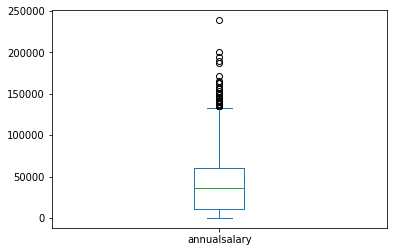

In [28]:
df.annualsalary.plot.box()

<Axes: xlabel='jobtitle'>

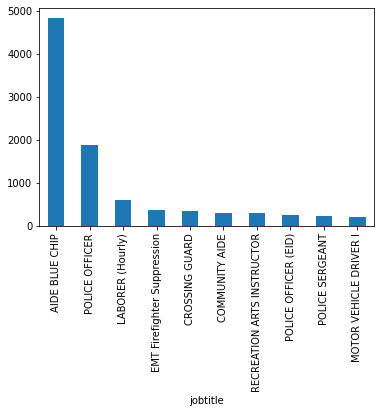

In [29]:
df.jobtitle.value_counts().iloc[:10].plot.bar()

<Axes: xlabel='jobtitle'>

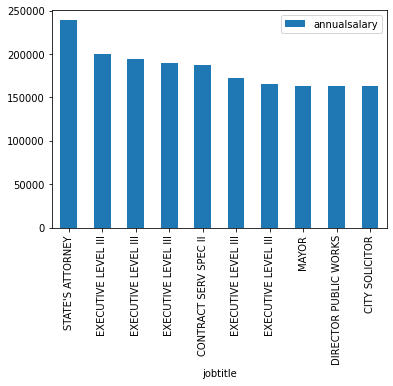

In [30]:
newdf=df[['jobtitle','annualsalary']].sort_values(by='annualsalary',ascending=False).head(10)
newdf.plot.bar(x='jobtitle')

<Axes: xlabel='agencyid'>

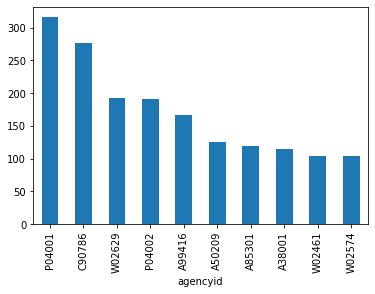

In [31]:
df.agencyid.value_counts().head(10).plot.bar()

<Axes: xlabel='hireyear'>

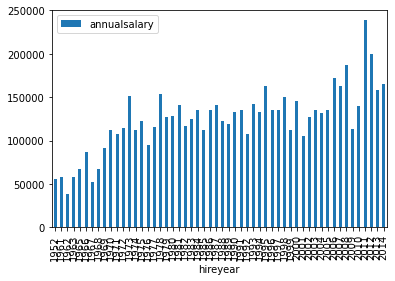

In [32]:
df.groupby(by='hireyear').max().plot.bar(y='annualsalary')

<Axes: xlabel='hireyear'>

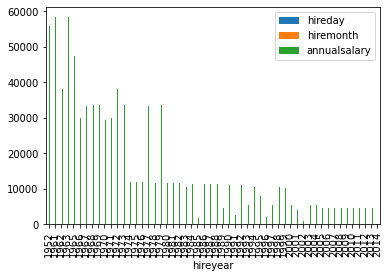

In [33]:
df.groupby(by='hireyear',dropna=True).min().plot.bar()

<Axes: xlabel='hiremonth'>

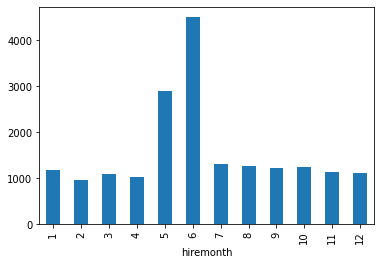

In [34]:
df.groupby(by='hiremonth')['name'].count().plot.bar()

In [35]:
df.head()

,name,jobtitle,agencyid,agency,hireday,hiremonth,hireyear,annualsalary
0,"Aaron,Keontae E",AIDE BLUE CHIP,W02200,Youth Summer,10,6,2013,11310.0
1,"Aaron,Patricia G",Facilities/Office Services II,A03031,OED-Employment Dev,24,10,1979,53428.0
2,"Aaron,Petra L",ASSISTANT STATE'S ATTORNEY,A29005,States Attorneys Office,25,9,2006,68300.0
3,"Abaineh,Yohannes T",EPIDEMIOLOGIST,A65026,HLTH-Health Department,23,7,2009,62000.0
4,"Abbene,Anthony M",POLICE OFFICER TRAINEE,A99416,Police Department,24,7,2013,43999.0


<Axes: >

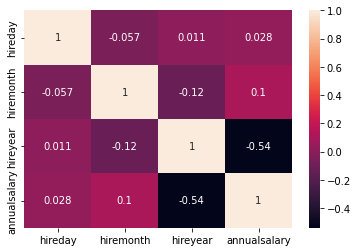

In [36]:
df=df.iloc[:,4:]
sns.heatmap(df.corr(),annot=True,color='green')

5. Splitting the data

In [37]:
X=np.array(df.iloc[:,:-1])
Y=np.array(df.iloc[:,-1]).reshape(-1,1)

In [38]:
len(X)

18911

In [39]:
len(Y)

18911

In [40]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=10)

In [41]:
Y_train=Y_train.reshape(-1,1)
Y_test=Y_test.reshape(-1,1)

In [42]:
print(len(X_train),len(X_test),len(Y_train),len(Y_test),sep='\n')

15128
3783
15128
3783


6. Data PreProcessing

In [43]:
stansplit=StandardScaler()

In [44]:
X_train=stansplit.fit_transform(X_train)
X_test=stansplit.fit_transform(X_test)
Y_train=stansplit.fit_transform(Y_train)
Y_test=stansplit.fit_transform(Y_test)

In [45]:
print(len(X_train),len(X_test),len(Y_train),len(Y_test),sep='\n')

15128
3783
15128
3783


7. Choosing the model

In [46]:
model = SVR(kernel='rbf')

8. Training the Model

In [47]:
model.fit(X_train,Y_train)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:1183: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

9. Testing the Model

In [48]:
Y_pred=model.predict(X_test).reshape(-1,1)

In [49]:
Y_pred=stansplit.inverse_transform(Y_pred)
Y_test=stansplit.inverse_transform(Y_test)
X_test=stansplit.inverse_transform(X_test)

In [50]:
model.score(X_test,Y_test)

-2.4620596495947513

In [51]:
r2_score(Y_test,Y_pred)

0.45375665047374136

In [52]:
mean_absolute_error(Y_test,Y_pred)

12720.157075913525

In [53]:
mean_squared_error(Y_test,Y_pred)

342291245.2456077

Text(0.5, 1.0, 'Actual v/s Predicted Values')

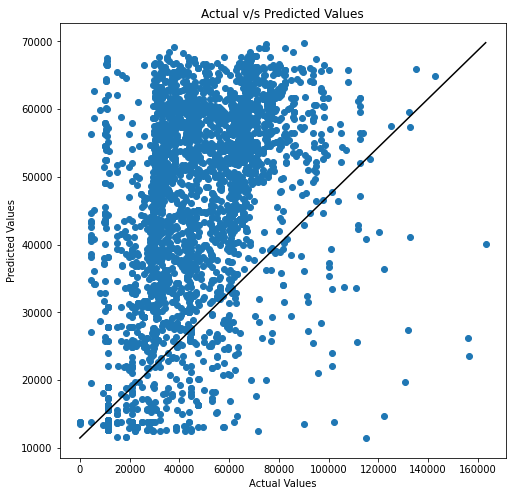

In [54]:
plt.figure(figsize=(8,8))
plt.plot([Y_test.min(),Y_test.max()],[Y_pred.min(),Y_pred.max()],color='black')
plt.scatter(Y_test,Y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title("Actual v/s Predicted Values")